In [224]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from helpers import *
from implementations import *
from preprocessing import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [225]:
data_path = "/Users/AliSawyer/Documents/EPFL/M1/CS-433_Machine_learning/course-repo/ML_course/projects/project1/data/dataset"
names = open(f"{data_path}/x_train.csv").readline().strip().split(",")[1:]
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

In [226]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

print(train_ids.shape)
print(test_ids.shape)

train_ids

(328135, 321)
(109379, 321)
(328135,)
(328135,)
(109379,)


array([     0,      1,      2, ..., 328132, 328133, 328134],
      shape=(328135,))

In [279]:
# add bias term (column of 1s) to the training data
# ones = np.ones(n)
# tx = np.column_stack((ones, x_train))

# preprocess data
tx_train, tx_test, features = preprocess(x_train, x_test, names)

# n is number of samples / data points
n = tx_train.shape[0]
# d is number of features
d = tx_train.shape[1]

tx_train

array([[ 1.        , -0.42032874, -0.00987575, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        ,  2.37909021, -0.00987575, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.42032874, -0.00987575, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 1.        , -0.42032874, -0.00987575, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.42032874, -0.00987575, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.42032874, -0.00987575, ...,  0.        ,
         0.        ,  0.        ]], shape=(328135, 257))

In [280]:
def random_undersample(x, y, seed=1):
    """ Randomly undersample the data to even out class imbalance:
        Randomly select only m samples from the MAJORITY class, where m equals the
        total number of samples in the dataset from the MINORITY class
    """
    np.random.seed(seed)
    labels, counts = np.unique(y, return_counts=True)
    m = counts.min()  # count of data points in minority class
    min_label = labels[counts.argmin()]  # minority class label
    maj_indices = np.where(y != min_label)[0]  # indices for data points in majority class
    min_indices = np.where(y == min_label)[0]  # indices for data points in minority class
    x_maj_only = x[maj_indices]  # dataset filtered for majority class only
    y_maj_only = y[maj_indices]  # dataset filtered for majority class only
    x_min_only = x[min_indices]  # dataset filtered for minority class only
    y_min_only = y[min_indices]  # dataset filtered for minority class only
    und_rand_idx = np.random.permutation(m)  # create ndarray of randomized indices for undersampling
    # undersample majority class data points using randomly generated indices
    x_und = x_maj_only[und_rand_idx]
    y_und = y_maj_only[und_rand_idx]
    # print(x_und.shape)
    # print(y_und.shape)

    # randomly generate indices for final reshuffle
    recombine_rand_idx = np.random.permutation(2 * m)
    # recombine with data points from the minority class
    x_recombine = np.concatenate([x_und, x_min_only])
    y_recombine = np.concatenate([y_und, y_min_only])
    
    return x_recombine[recombine_rand_idx], y_recombine[recombine_rand_idx]
    

def split_data(x, y, ratio, seed=1):
    """
    Split data into training and test sets based on provided ratio.
    """
    # set randomization seed for reproducibility
    np.random.seed(seed)
    n = x.shape[0]
    rand_idx = np.random.permutation(n)  # create ndarray of randomized indices
    training_size = int(np.floor(ratio * n))
    rand_idx_tr = rand_idx[:training_size]  # get randomized indices for the training set
    rand_idx_te = rand_idx[training_size:]  # get randomized indices for the test set

    x_tr = x[rand_idx_tr]  # use the training set of randomized indices to sample from x
    x_te = x[rand_idx_te]  # use the test set of randomized indices to sample from x
    y_tr = y[rand_idx_tr]  # use the training set of randomized indices to sample from y
    y_te = y[rand_idx_te]  # use the test set of randomized indices to sample from y

    # RANDOM UNDERSAMPLING to even out class imbalance
    x_tr, y_tr = random_undersample(x_tr, y_tr)

    return x_tr, x_te, y_tr, y_te


# use unusually high ratio since we will be randomly undersampling the training data to address class imbalance
ratio = 0.95
x_tr, x_te, y_tr, y_te = split_data(tx_train, y_train, ratio)
print(f"Split dataset shapes:\tx_train: {x_tr.shape}\ttx_test:{x_te.shape}\ty_train: {y_tr.shape}\ty_test: {y_te.shape}")

Split dataset shapes:	x_train: (55190, 257)	tx_test:(16407, 257)	y_train: (55190,)	y_test: (16407,)


[27595 27595]


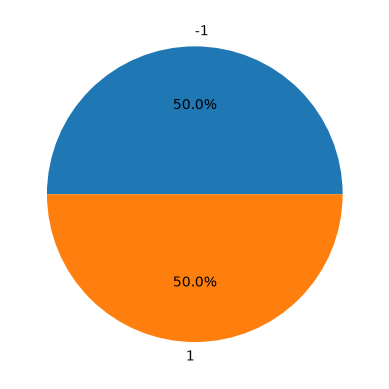

In [281]:
# Visualize breakdown of labels in y_tr
vals, counts = np.unique(y_tr, return_counts=True)
print(counts)
plt.pie(counts, labels=vals, autopct='%1.1f%%')
plt.show()

# class imbalance is approx 1:10 negative to positive
# https://machinelearningmastery.com/what-is-imbalanced-classification/

In [265]:
# Plotting and scoring functions
# Attribution: Code help from Claude AI chat

def line_chart_train_test(x, y1, y2):
    # plt.plot(x, y)
    plt.semilogx(x, y1, color="b", marker=".", label="Train error")
    plt.semilogx(x, y2, color="c", marker=".", label="Test error")
    plt.xlabel("lambda")
    plt.ylabel("error")
    leg = plt.legend()
    plt.show()


def ordered_bar_chart(labels, values):
    labels = np.array(labels)
    values = np.array(values)
    order = np.argsort(values)   # ascending
    colors = plt.cm.tab10(np.arange(len(values)))
    plt.bar(labels[order], values[order], color=colors)
    plt.title("F1 Score Comparison for Different Learning Algorithms")
    plt.xticks(rotation=45, ha="right")
    plt.show()


def compute_f1(y_pred, y_test):
    """ Calculate F1 score: 2TP / (2TP + FP + FN) """
    tp = np.sum((y_pred == 1) & (y_test == 1))
    fp = np.sum((y_pred == 1) & (y_test == -1))
    fn = np.sum((y_pred == -1) & (y_test == 1))
    
    f1 = 2 * tp / (2 * tp + fp + fn)
    return f1.item()


def compute_accuracy(y_pred, y_test):
    """ Calculate accuracy: correct predictions over total predictions
        (TP + TN) / (TP + TN + FP + TN) """
    correct = np.sum(y_pred == y_test)
    total = y_pred.shape[0]
    
    return correct / total

In [231]:
def linear_classifier(x, w):
    """ Super simple linear classifier:
        Returns predictiction sign() (+/-1) of dot product of x and w
    """
    predictions = x @ w
    return np.sign(predictions)


test_f1_scores = []

# Linear regression
# Regular full-batch gradient descent first

initial_w = np.zeros(d)
max_iters = 1000
gamma = 0.1

# run training algorithm on training data to get optimal w
w_msegd, loss_msegd_tr = mean_squared_error_gd(y_tr, x_tr, initial_w, max_iters, gamma)

# get test loss
loss_msegd_te = calculate_mse(y_te, x_te, w_msegd)
print(f"Test loss: {loss_msegd_te}")

# using weights from gradient descent, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_msegd = linear_classifier(x_te, w_msegd)
f1_msegd = compute_f1(pred_msegd, y_te)
test_f1_scores.append(f1_msegd)
print(test_f1_scores)

Test loss: 0.13158404142707122
[0.08380258363696588]


In [232]:
# stochastic GD
initial_w = np.zeros(d)
max_iters = 5000
gamma = 0.0001

# run training algorithm (SGD) on training data to get optimal w
w_msesgd, loss_msesgd_tr = mean_squared_error_sgd(y_tr, x_tr, initial_w, max_iters, gamma)

# using weights from SGD, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_msesgd = linear_classifier(x_te, w_msesgd)
f1_msesgd = compute_f1(pred_msesgd, y_te)
test_f1_scores.append(f1_msesgd)
print(test_f1_scores)

[0.08380258363696588, 0.09869468322190385]


In [233]:
# Least squares

# run training algorithm on training data to get optimal w
w_ls, loss_ls_te = least_squares(y_tr, x_tr)

loss_ls_te = calculate_mse(y_te, x_te, w_ls)
print(loss_ls_te)

# using weights from least squares, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_ls = linear_classifier(x_te, w_ls)
f1_ls = compute_f1(pred_ls, y_te)
test_f1_scores.append(f1_ls)

0.1315978849523263


In [234]:
def find_best_lambda(f, f_args_tr, f_args_te):
    """ Compare over a range of lambda values to find one that results in lowest test error. 
        Args:
            f: Learning algorithm (function name) to run
            f_args_tr: Dict for positional args with which to run f for training
            f_args_te: Dict for positional args with which to run f for testing
        Returns: Best lambda value (based on test error)
    """
    # include 0 in the lambda values to try
    lambdas = np.concatenate(([0], np.logspace(-10, 0, 15)))
    # lambda_ = 0.01
    
    tr_losses = np.zeros(len(lambdas))
    te_losses = np.zeros(len(lambdas))
    for i, lambda_ in enumerate(lambdas):
        if "max_iters" in f_args_tr:  # we are doing GD, need initial_w
            initial_w_tr = np.zeros(d)
            initial_w_te = np.zeros(d)
            f_args_tr["initial_w"] = initial_w_tr
            f_args_te["initial_w"] = initial_w_te
        w_tr, loss_tr = f(**f_args_tr, lambda_=lambda_)
        w_te, loss_te = f(**f_args_te, lambda_=lambda_)
        tr_losses[i] = loss_tr
        te_losses[i] = loss_te
        print(f"Lambda: {lambda_}\tTraining loss: {loss_tr}\tTest loss: {loss_te}")
    
    min_idx_loss_tr = np.argmin(tr_losses)
    min_idx_loss_te = np.argmin(te_losses)
    best_lambda_tr = lambdas[min_idx_loss_tr]
    best_lambda_te = lambdas[min_idx_loss_te]
    print(f"Best lambda values:\tTrain: {best_lambda_tr} at idx {min_idx_loss_tr}\tTest: {best_lambda_te} at idx {min_idx_loss_te}")
    line_chart_train_test(lambdas, tr_losses, te_losses)

    return best_lambda_te

Lambda: 0.0	Training loss: 0.1341880136980107	Test loss: 0.1310005692300156
Lambda: 1e-10	Training loss: 0.13418801369801073	Test loss: 0.1310005692300156
Lambda: 5.179474679231202e-10	Training loss: 0.13418801369801128	Test loss: 0.13100056923001574
Lambda: 2.6826957952797275e-09	Training loss: 0.1341880136980266	Test loss: 0.13100056923001982
Lambda: 1.389495494373136e-08	Training loss: 0.1341880136984364	Test loss: 0.13100056923012887
Lambda: 7.196856730011529e-08	Training loss: 0.13418801370922948	Test loss: 0.13100056923303563
Lambda: 3.727593720314938e-07	Training loss: 0.13418801397316302	Test loss: 0.13100056930838885
Lambda: 1.9306977288832498e-06	Training loss: 0.13418801862172425	Test loss: 0.13100057101811927
Lambda: 1e-05	Training loss: 0.13418805131577696	Test loss: 0.13100059444803835
Lambda: 5.1794746792312125e-05	Training loss: 0.13418819991489211	Test loss: 0.1310007472673573
Lambda: 0.0002682695795279727	Training loss: 0.13418979901041955	Test loss: 0.131002503599014

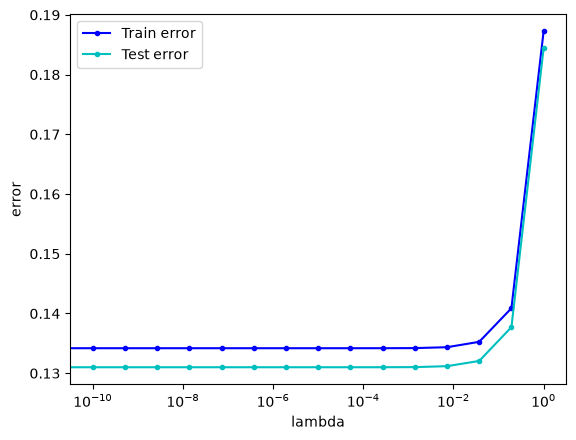

Test loss comparison:	Ridge regression: 0.1315978849523263	 vs Least squares: 0.1315978849523263


In [235]:
# Ridge regression
args_tr = { "y": y_tr, "tx": x_tr }
args_te = { "y": y_te, "tx": x_te }
best_lambda_te = find_best_lambda(ridge_regression, args_tr, args_te)

# run training algorithm on training data with best lambda to get optimal w
# with lambda_ = 0, this is exactly the same as least squares
w_rr, loss_rr_tr = ridge_regression(y_tr, x_tr, best_lambda_te)

# get test loss for ridge regression (MSE)
loss_rr_te = calculate_mse(y_te, x_te, w_rr)
# compare with least squares
loss_ls_te = calculate_mse(y_te, x_te, w_ls)
print(f"Test loss comparison:\tRidge regression: {loss_rr_te}\t vs Least squares: {loss_ls_te}")

# test_losses.append(loss_rr_te.item())
# print(test_losses)

In [288]:
# Logistic regression
initial_w = np.zeros(d)
max_iters = 1000
gamma = 0.1

# convert y labels from -1/+1 to 0/1 to work with logistic loss function
y_tr_conv = (y_tr + 1) / 2
y_te_conv = (y_te + 1) / 2

# run training algorithm on training data to get optimal w
w_log, loss_log = logistic_regression(y_tr_conv, x_tr, initial_w, max_iters, gamma)
print(f"Logistic regression training loss: {loss_log}")
# also calculate negative LL loss on TEST data to compare
loss_log_te = calculate_neg_ll_loss(y_te_conv, x_te, w_log)
print(f"Logistic regression test loss: {loss_log_te}")

# only sign(x @ w) matters to predict class, so we can also use linear_classifier() here
pred_log = linear_classifier(x_te, w_log)
# get F1 score for comparison with other models
f1_log = compute_f1(pred_log, y_te)
test_f1_scores.append(f1_log)
accuracy = compute_accuracy(pred_log, y_te)
print(f"F1 score: {f1_log}\tAccuracy: {accuracy}")

Iteration 0:	Loss: 0.6201635003341129
Iteration 100:	Loss: 0.47197575760583027
Iteration 200:	Loss: 0.468463553958478
Iteration 300:	Loss: 0.46704992828478337
Iteration 400:	Loss: 0.46625645795699333
Iteration 500:	Loss: 0.46575765742575775
Iteration 600:	Loss: 0.46542194227812866
Iteration 700:	Loss: 0.4651840251598888
Iteration 800:	Loss: 0.46500806437292064
Iteration 900:	Loss: 0.4648730659919668
Logistic regression training loss: 0.4647670865617891
Logistic regression test loss: 0.48439188833625935
F1 score: 0.3576947842884739	Accuracy: 0.7568111172060705


Iteration 0:	Loss: 0.6201635003341129
Iteration 100:	Loss: 0.47197575760583027
Iteration 200:	Loss: 0.468463553958478
Iteration 300:	Loss: 0.46704992828478337
Iteration 400:	Loss: 0.46625645795699333
Iteration 0:	Loss: 0.6269333681153542
Iteration 100:	Loss: 0.22551445835168318
Iteration 200:	Loss: 0.2182056169334255
Iteration 300:	Loss: 0.21593074038843704
Iteration 400:	Loss: 0.21478119857211317
Lambda: 0.0	Training loss: 0.4657616924923825	Test loss: 0.2140655741742445
Iteration 0:	Loss: 0.6201635003341129
Iteration 100:	Loss: 0.4719757576186073
Iteration 200:	Loss: 0.46846355397146083
Iteration 300:	Loss: 0.4670499282993859
Iteration 400:	Loss: 0.46625645797288034
Iteration 0:	Loss: 0.6269333681153542
Iteration 100:	Loss: 0.22551445839468465
Iteration 200:	Loss: 0.2182056169731526
Iteration 300:	Loss: 0.21593074042484936
Iteration 400:	Loss: 0.21478119860643585
Lambda: 1e-10	Training loss: 0.4657616925089819	Test loss: 0.21406557420752362
Iteration 0:	Loss: 0.6201635003341129
Itera

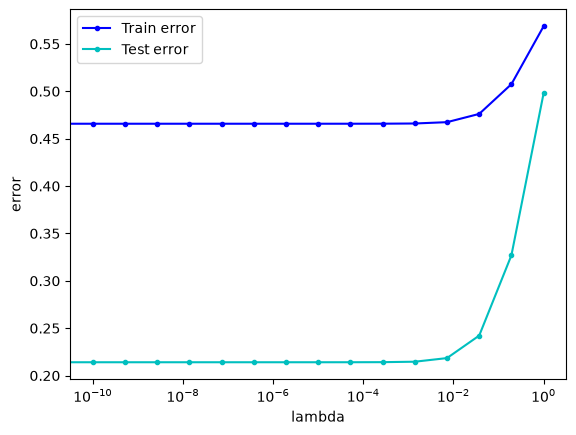

In [285]:
# Regularized logistic regression
max_iters = 500
gamma = 0.1
args_tr = { "y": y_tr_conv, "tx": x_tr, "max_iters": max_iters, "gamma": gamma }
args_te = { "y": y_te_conv, "tx": x_te, "max_iters": max_iters, "gamma": gamma }
best_lambda_te = find_best_lambda(reg_logistic_regression, args_tr, args_te)

# with lambda_ = 0, exactly the same as regular (unpenalized) logistic regression

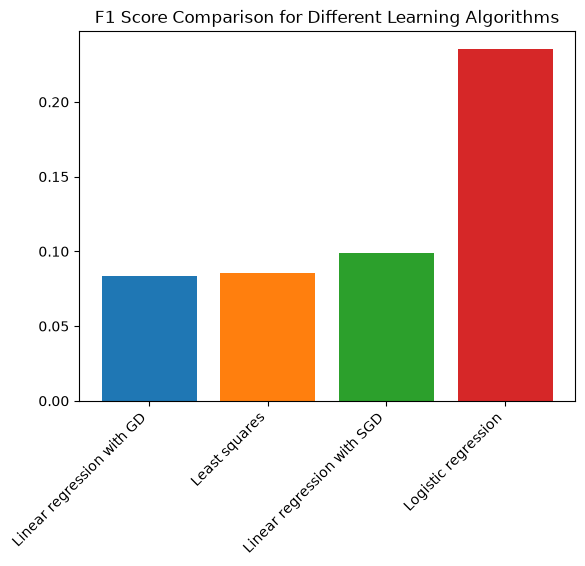

In [238]:
# compare models
labels = ["Linear regression with GD", "Linear regression with SGD", "Least squares", "Logistic regression"]
ordered_bar_chart(labels, test_f1_scores)

In [246]:
# check relative importance/influence of features on the prediction
# w_log is best weights found so far

most_impact_indices = np.argsort(np.abs(w_log))[::-1][:10]
most_impact_features = np.array(features)[most_impact_indices]
most_impact_features

array(['bias', '_RACE=1', '_AGEG5YR', 'RENTHOM1=1', 'SEX', 'MARITAL=5',
       'RENTHOM1=2', 'GENHLTH', '_RACEG21', 'EMPLOY1=1'], dtype='<U16')